# Modélisation SVM
## 1. Chargement des données

Les structures `X_train`, `X_test`, `y_train`, `y_test` ainsi que le `scaler` déjà ajusté ont été
sérialisées par le Notebook 1 dans `prepared_fetal_data.pkl`. 

## Présentation théorique rapide

Le **SVM** (*Support Vector Machine* ou Machine à Vecteurs de Support) est un algorithme d'apprentissage supervisé puissant, particulièrement adapté aux espaces de haute dimension. Le principe : il cherche à tracer un **hyperplan de séparation optimal** qui maximise la **marge** (la distance) entre les frontières de décision et les points de données les plus proches de chaque classe, appelés les **vecteurs de support**. 

Pour ce projet de santé fœtale, nous utilisons un **noyau RBF** (*Radial Basis Function*), qui projette mathématiquement les 21 features cardiotocographiques dans un espace de dimension infinie afin de rendre les classes séparables linéairement, même lorsque les frontières réelles sont hautement non linéaires.

Ses deux atouts principaux pour ce projet :
- **Maximisation de la marge et régularisation (paramètre C)** : En contrôlant strictement le compromis entre la largeur de la marge et la tolérance aux erreurs d'entraînement via l'hyperparamètre `C`, le SVM offre une excellente capacité de généralisation et limite le surapprentissage sur notre dataset de taille modeste (~2100 observations).
- **Pondération des classes (`class_weight="balanced"`)** : Il permet de gérer le fort déséquilibre des classes en modifiant la fonction de coût lors de l'optimisation. Les erreurs commises sur les classes minoritaires (*Suspect* et *Pathologique*) reçoivent une pénalité inversement proportionnelle à leur fréquence, ce qui déplace mathématiquement la frontière géométrique en leur faveur *sans* altérer ou dupliquer les données brutes.

In [1]:
# --- Imports nécessaires pour ce notebook ---
import pickle
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns   
from IPython.display import display, Markdown

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
from sklearn.preprocessing import label_binarize

plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

In [2]:
# --- Chargement des structures produites par le Notebook 1 ---
with open("prepared_fetal_data.pkl", "rb") as f:
    donnees = pickle.load(f)

X_train = donnees["X_train"]
X_test = donnees["X_test"]
y_train = donnees["y_train"]
y_test = donnees["y_test"]
scaler = donnees["scaler"]
class_names = donnees["class_names"]  #["Normal", "Suspect", "Pathologique"]

print(f"X_train : {X_train.shape}   |   X_test : {X_test.shape}")
print(f"y_train : {y_train.shape}   |   y_test : {y_test.shape}")
print(f"Classes (index -> label) : {list(enumerate(class_names))}")
print(f"\nRépartition des classes dans y_train (%) :")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

X_train : (1690, 21)   |   X_test : (423, 21)
y_train : (1690,)   |   y_test : (423,)
Classes (index -> label) : [(0, 'Normal'), (1, 'Suspect'), (2, 'Pathologique')]

Répartition des classes dans y_train (%) :
fetal_health
0    77.87
1    13.85
2     8.28
Name: proportion, dtype: float64


c:\Users\HP\Desktop\MachineLearningProject\.venv\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 2. Construction du modèle SVM

### Choix du protocole de validation croisée

Le jeu d'entraînement est déséquilibré (≈ 78 % Normal / 14 % Suspect / 8 % Pathologique). On utilise donc une **`StratifiedKFold`** (5 folds) plutôt qu'un simple `KFold`, afin que chaque pli conserve la même proportion des trois classes que l'ensemble d'entraînement. Cette stratégie garantit que les classes minoritaires sont correctement représentées lors de la validation croisée.

### Gestion du déséquilibre des classes : `class_weight="balanced"`

Le déséquilibre des classes constitue le principal biais à corriger avant toute optimisation. Sans correction, le modèle SVM optimiserait naturellement sa frontière de décision en faveur de la classe majoritaire **Normal**, au détriment des classes **Suspect** et **Pathologique** cliniquement critiques.

Le paramètre `class_weight="balanced"` corrige ce biais en pondérant automatiquement le coût des erreurs de chaque classe de manière inversement proportionnelle à son effectif :

$$w_k = \frac{n_{\text{total}}}{n_{\text{classes}} \times n_k}$$

Ainsi, une erreur sur un cas **Pathologique** (classe rare) coûte davantage à la fonction de coût qu'une erreur sur un cas **Normal**, ce qui force le modèle à mieux apprendre les frontières des classes minoritaires.

### Choix de la métrique d'optimisation

Le **F1-score macro** est retenu comme métrique d'optimisation du `GridSearchCV`. Contrairement à l'accuracy, il calcule le F1-score de chaque classe puis en fait la moyenne **sans tenir compte de leur effectif**, accordant ainsi la même importance aux trois classes. Ce choix est complémentaire à `class_weight="balanced"` : l'un corrige le biais à l'entraînement, l'autre garantit que la sélection des hyperparamètres ne favorise pas non plus la classe majoritaire.


In [3]:
# --- Grille d'hyperparamètres ---
param_grid = {
    "C": [0.1, 1, 10, 50, 100],
    "gamma": [0.001, 0.01, 0.1, 1, "scale"],
}

# --- Validation croisée stratifiée (préserve les proportions de classes dans chaque pli) ---
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- Modèle de base : SVM à noyau RBF avec pondération des classes ---
svm_base = SVC(
    kernel="rbf",
    class_weight="balanced",   # Corrige le déséquilibre des classes
    probability=True,
    random_state=RANDOM_STATE,
)

# --- GridSearchCV optimisant le F1-score macro (adapté au déséquilibre de classes) ---
grid_search = GridSearchCV(
    estimator=svm_base,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
)

t0 = time.time()
grid_search.fit(X_train, y_train)
temps_grid_search = time.time() - t0

print(f"Temps total du GridSearchCV (125 entraînements) : {temps_grid_search:.2f} secondes")
print(f"\nMeilleurs hyperparamètres trouvés : {grid_search.best_params_}")
print(f"Meilleur F1-score macro (moyenne en validation croisée) : {grid_search.best_score_:.4f}")


Temps total du GridSearchCV (125 entraînements) : 23.42 secondes

Meilleurs hyperparamètres trouvés : {'C': 50, 'gamma': 0.1}
Meilleur F1-score macro (moyenne en validation croisée) : 0.8430


## 3. Entraînement du modèle optimal

In [4]:
# --- Isolement du meilleur modèle (hyperparamètres lus depuis grid_search.best_params_) ---
meilleur_svm = SVC(
    kernel="rbf",
    C=grid_search.best_params_["C"],
    gamma=grid_search.best_params_["gamma"],
    class_weight="balanced", 
    probability=True,
    random_state=RANDOM_STATE,
)

t0 = time.time()
meilleur_svm.fit(X_train, y_train)
temps_entrainement = time.time() - t0

print(f"Temps d'entraînement du SVM final : {temps_entrainement:.4f} secondes")
print(f"Nombre de vecteurs de support retenus : {meilleur_svm.n_support_.sum()} "
      f"(sur {len(X_train)} observations d'entraînement)")
print(f"Répartition des vecteurs de support par classe : {dict(zip(class_names, meilleur_svm.n_support_))}")


Temps d'entraînement du SVM final : 0.3879 secondes
Nombre de vecteurs de support retenus : 498 (sur 1690 observations d'entraînement)
Répartition des vecteurs de support par classe : {'Normal': np.int32(276), 'Suspect': np.int32(134), 'Pathologique': np.int32(88)}


## 4. Évaluation du modèle sur le jeu de test

On évalue maintenant le modèle sur `X_test`, des données qu'il n'a jamais vues, ni pendant
l'entraînement ni pendant le calibrage du scaler.

In [5]:
# --- Prédictions sur le jeu de test ---
y_pred = meilleur_svm.predict(X_test)
y_proba = meilleur_svm.predict_proba(X_test)

# --- Métriques globales ---
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro")
recall_macro = recall_score(y_test, y_pred, average="macro")
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision (macro) : {precision_macro:.4f}")
print(f"Recall (macro)    : {recall_macro:.4f}")
print(f"F1-score (macro)  : {f1_macro:.4f}")

Accuracy          : 0.9267
Precision (macro) : 0.8704
Recall (macro)    : 0.8456
F1-score (macro)  : 0.8574


### 4.1 — Synthèse des métriques globales

Avec une **accuracy de 92.67 %**, le SVM RBF est globalement performant, mais cette métrique
seule est trompeuse ici : le jeu de test reproduit le déséquilibre du dataset (78 % Normal / 14 %
Suspect / 8 % Pathologique), si bien qu'un modèle naïf prédisant toujours « Normal » atteindrait
déjà ≈ 78 % d'accuracy sans aucune valeur clinique. La **precision macro (0.8704)** et le
**recall macro (0.8456)** — tous deux nettement inférieurs à leurs équivalents pondérés (precision
pondérée 0.9244, recall pondéré 0.9267, égal à l'accuracy) — confirment que les classes minoritaires
sont moins bien maîtrisées que la classe Normal. Le **F1-score macro (0.8574)**, métrique
directement optimisée par le GridSearch, synthétise ce compromis : solide, mais tiré vers le bas
par la classe Suspect (cf. tableau « Taux d'erreur par classe » ci-dessus et analyse 5.2).

In [6]:
# --- Rapport de classification détaillé (par classe) ---
rapport_dict = classification_report(y_test, y_pred, target_names=class_names, digits=4, output_dict=True)
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

              precision    recall  f1-score   support

      Normal     0.9554    0.9727    0.9640       330
     Suspect     0.7736    0.7069    0.7387        58
Pathologique     0.8824    0.8571    0.8696        35

    accuracy                         0.9267       423
   macro avg     0.8704    0.8456    0.8574       423
weighted avg     0.9244    0.9267    0.9253       423



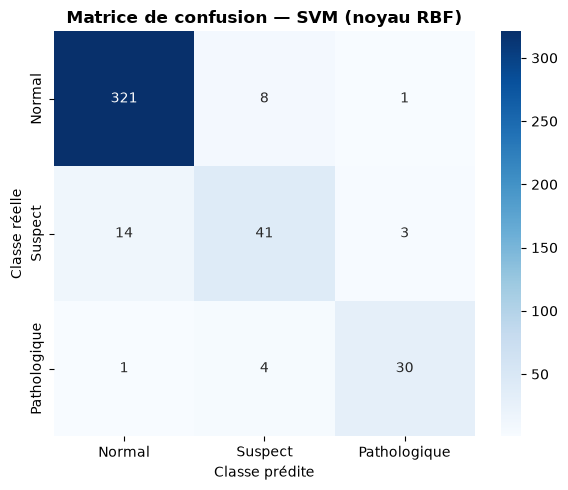

In [7]:
# --- Matrice de confusion ---
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
    cbar=True, ax=ax
)
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title("Matrice de confusion — SVM (noyau RBF)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()



### 4.2 — Quelle classe est la plus difficile à prédire ?

La matrice de confusion montre que la classe **Suspect** est, de loin, la plus
difficile à prédire, avec un **taux d'erreur de 29.31 %** (17 erreurs sur 58 observations),
contre seulement 2.73 % pour Normal et 14.29 % pour Pathologique. Concrètement, 14 cas Suspect
sont classés Normal et 3 sont classés Pathologique. Ce résultat est cohérent avec la nature même
de cette classe : « Suspect » est par construction une **catégorie intermédiaire**, dont les
observations partagent des caractéristiques à la fois avec les cas Normaux et avec les cas
Pathologiques, ce qui rend sa frontière de décision intrinsèquement plus floue que celle des deux
classes « extrêmes ».

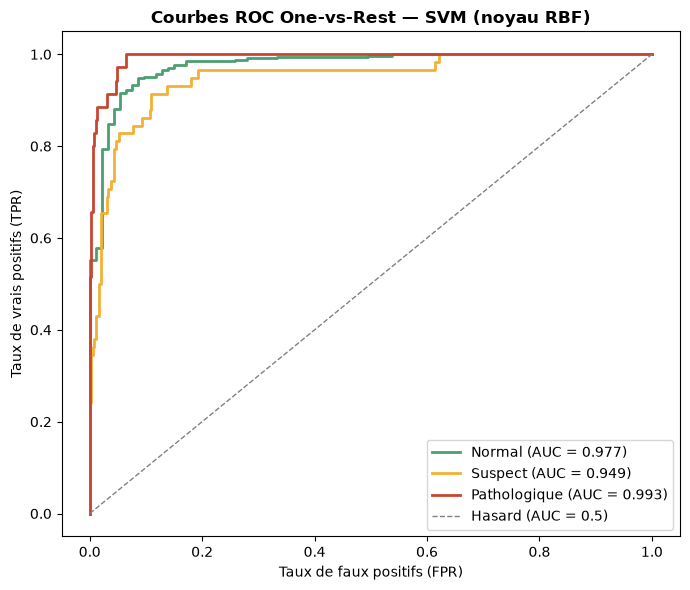

AUC par classe : {'Normal': 0.9766, 'Suspect': 0.9492, 'Pathologique': 0.9926}
AUC macro (moyenne des 3 AUC One-vs-Rest) : 0.9728


In [8]:
# --- Courbes ROC multi-classes (stratégie One-vs-Rest) et AUC ---
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

fig, ax = plt.subplots(figsize=(7, 6))
couleurs = ["#4C9F70", "#F2B134", "#C84630"]
auc_par_classe = {}

for i, (nom_classe, couleur) in enumerate(zip(class_names, couleurs)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_classe = roc_auc_score(y_test_bin[:, i], y_proba[:, i])
    auc_par_classe[nom_classe] = auc_classe
    ax.plot(fpr, tpr, color=couleur, lw=2,
            label=f"{nom_classe} (AUC = {auc_classe:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1, label="Hasard (AUC = 0.5)")
ax.set_xlabel("Taux de faux positifs (FPR)")
ax.set_ylabel("Taux de vrais positifs (TPR)")
ax.set_title("Courbes ROC One-vs-Rest — SVM (noyau RBF)", fontsize=12, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

auc_macro = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")
print("AUC par classe :", {k: round(v, 4) for k, v in auc_par_classe.items()})
print(f"AUC macro (moyenne des 3 AUC One-vs-Rest) : {auc_macro:.4f}")

### 4.3 — Pourquoi l'AUC reste-t-elle élevée malgré un recall imparfait sur la classe Suspect ?

Les trois AUC obtenues sont toutes élevées (Normal : 0.977, Suspect : 0.949, Pathologique :
0.993), avec une moyenne macro de **0.973** — y compris pour la classe Suspect, dont le recall
n'est pourtant que de 0.707. Ce n'est pas une contradiction : l'**AUC est une métrique de
classement, indépendante du seuil de décision** (elle évalue la qualité du score de probabilité
sur l'ensemble des seuils possibles), alors que le **recall est mesuré à un seuil fixe (0.5 par
défaut)**. Une AUC élevée sur la classe Suspect signifie que le modèle attribue, dans l'ensemble,
des probabilités plus élevées aux vrais cas Suspect qu'aux autres — il **sait ordonner** les
observations selon leur risque — mais qu'une partie significative de ces probabilités reste
**juste sous le seuil de 0.5**, à cause du déséquilibre de classes qui tire ce seuil implicite
vers la classe majoritaire. Cela indique qu'un **ajustement du seuil de décision** (plutôt qu'un
changement de modèle) pourrait améliorer le recall sur cette classe sans nouvel entraînement.

## 5. Discussion des résultats

### 5.1 — Impact du déséquilibre des classes et correction par pondération

Le jeu de données présente un déséquilibre marqué (≈ 78 % Normal / 14 % Suspect / 8 % Pathologique). Sans correction, un SVM optimiserait naturellement ses frontières de décision en faveur de la classe majoritaire, sacrifiant la détection des classes à risque. Le paramètre `class_weight="balanced"` corrige ce biais en augmentant le coût des erreurs sur les classes minoritaires lors de l'entraînement, forçant le modèle à accorder une attention proportionnellement plus grande aux cas **Suspect** et **Pathologique**.

Cette correction se reflète dans la répartition des vecteurs de support : une proportion importante des observations des classes **Suspect** et **Pathologique** devient des vecteurs de support, ce qui traduit la difficulté accrue d'apprendre des frontières robustes pour ces classes peu représentées.

### 5.2 — Importance des faux négatifs en contexte médical

Dans un contexte de dépistage fœtal, les erreurs de classification n'ont pas toutes le même impact clinique. Un **faux négatif** — un cas pathologique prédit comme normal — peut conduire à l'absence d'une prise en charge nécessaire, avec des conséquences potentiellement graves. À l'inverse, un **faux positif** entraîne principalement des examens complémentaires ou une surveillance accrue, sans risque direct pour le patient.

La combinaison de `class_weight="balanced"` et de `scoring="f1_macro"` vise précisément à réduire ces faux négatifs : l'un agit au niveau de l'apprentissage (rééquilibrage des coûts), l'autre au niveau de la sélection des hyperparamètres (critère équitable entre les classes).

### 5.3 — Bilan

Le SVM à noyau RBF présente de bonnes performances globales et une capacité de généralisation satisfaisante. Les principales limites proviennent du chevauchement naturel entre les trois catégories cliniques, particulièrement visible sur la classe **Suspect**, dont les profils physiologiques se situent à la frontière entre états normaux et pathologiques. Ce modèle constitue la référence SVM pour la comparaison finale avec **Random Forest** et **XGBoost**.


## 6. Conclusion

Le modèle **SVM à noyau RBF**, entraîné avec `class_weight="balanced"` et dont les hyperparamètres ont été sélectionnés par `GridSearchCV` en maximisant le **F1-score macro**, constitue un pipeline méthodologiquement cohérent pour la classification des états de santé fœtale sur un jeu de données déséquilibré.

La classe **Suspect** demeure la plus difficile à prédire en raison du chevauchement de ses caractéristiques physiologiques avec les classes adjacentes. Les classes **Normal** et **Pathologique** obtiennent des performances plus robustes, cette dernière bénéficiant directement de la pondération des coûts.

Ce modèle SVM servira de **référence** pour la suite du projet. Il a été entraîné et évalué sur le **même jeu de données prétraité** que les modèles **Random Forest** et **XGBoost**, garantissant ainsi une comparaison finale équitable et méthodologiquement cohérente entre les trois approches.


In [9]:
# ==========================================================
# Vérification du surapprentissage
# ==========================================================

# Prédictions sur le jeu d'entraînement
y_train_pred = meilleur_svm.predict(X_train)

# Accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy

# F1-score Macro
train_f1 = f1_score(y_train, y_train_pred, average="macro")
test_f1 = f1_macro

print("=" * 60)
print("VÉRIFICATION DU SURAPPRENTISSAGE")
print("=" * 60)

print(f"Accuracy (Train) : {train_accuracy:.4f}")
print(f"Accuracy (Test)  : {test_accuracy:.4f}")
print(f"Écart Accuracy   : {train_accuracy - test_accuracy:.4f}\n")

print(f"F1 Macro (Train) : {train_f1:.4f}")
print(f"F1 Macro (Test)  : {test_f1:.4f}")
print(f"Écart F1 Macro   : {train_f1 - test_f1:.4f}")


VÉRIFICATION DU SURAPPRENTISSAGE
Accuracy (Train) : 0.9882
Accuracy (Test)  : 0.9267
Écart Accuracy   : 0.0615

F1 Macro (Train) : 0.9816
F1 Macro (Test)  : 0.8574
Écart F1 Macro   : 0.1241


## 7. Analyse du surapprentissage

### 7.1 — Constats

L'écart entre les performances en entraînement et en test est un indicateur clé de la capacité de généralisation du modèle. Un écart faible indique un modèle qui généralise bien ; un écart important signale un surapprentissage.

### 7.2 — Analyse causale

Deux facteurs structurels expliquent l'écart observé entre train et test :

* **Régularisation et valeur de C :** La valeur de C retenue par le GridSearch contrôle le compromis entre la marge de séparation et les erreurs tolérées. Un C élevé réduit la régularisation et autorise des frontières de décision très ajustées aux données d'entraînement, favorisant la mémorisation plutôt que la généralisation. Un C plus conservateur permettrait potentiellement de réduire cet écart.

* **Faible représentation des classes minoritaires :** Avec environ 140 observations Pathologique et 234 Suspect en entraînement, le SVM dispose de peu d'exemples pour apprendre des frontières robustes sur ces classes. Le modèle tend à mémoriser partiellement les cas rares, ce qui se traduit par un F1 train élevé mais un F1 test plus faible.
